In [1]:
import sys
sys.path.insert(0, '..')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from shared.plot_utilities import (
    setup_notebook_display,
    plot_strategy_radar_charts,
    plot_bar_chart,
    sort_player_types,
)

setup_notebook_display(figsize=(10, 6))

df = pd.read_csv('../performance/player_strength_panel.csv')
print(f'Loaded {len(df)} rows, {df["player_type"].nunique()} player types, {df["game_id"].nunique()} games')
df.head()

Loaded 2856 rows, 16 player types, 357 games


,game_id,player_id,player_type,civilization,experiment,weighted_strength,is_winner,max_weighted_strength,relative_strength,adjusted_strength,turn,map_type,map_size,difficulty,game_speed,victory_type,victory_player_id,score,score_rank,score_ratio,survival_turn,input_tokens,reasoning_tokens,output_tokens,strategy_changes,persona_changes,research_changes,policy_changes,nuke,use_nuke,domination_ratio,culture_ratio,diplomatic_ratio,science_ratio,tradition,authority,progress,fealty,statecraft,artistry,industry,imperialism,rationalism,freedom,autocracy,order,condition,strategy_change_rate,persona_change_rate
0,00a56d80-647b-405d-be7f-8e3ab71315ae,0,Vanilla,Persia,2026-oss-v-glm-standard,0.009872,0,0.589365,0.016750,0.157398,500,Vox_Deorum,Standard,Prince,Standard,Time,5,2521,4,0.5304,499,0.0,0.0,0.0,266,1,0,0,50.0,50.0,0.2605,0.1403,0.0401,0.5591,NaN,21.0,NaN,NaN,NaN,170.0,NaN,296.0,NaN,379.0,NaN,NaN,2026-oss-v-glm-standard,0.533066,0.002004
1,00a56d80-647b-405d-be7f-8e3ab71315ae,1,Vanilla,The Huns,2026-oss-v-glm-standard,0.010467,0,0.589365,0.017760,0.071966,500,Vox_Deorum,Standard,Prince,Standard,Time,5,1806,7,0.3800,499,0.0,0.0,0.0,242,1,0,0,50.0,50.0,0.4600,0.0000,0.0000,0.5400,NaN,15.0,NaN,164.0,NaN,NaN,NaN,295.0,NaN,NaN,453.0,398.0,2026-oss-v-glm-standard,0.484970,0.002004
2,00a56d80-647b-405d-be7f-8e3ab71315ae,2,Vanilla,Ethiopia,2026-oss-v-glm-standard,0.029452,0,0.589365,0.049973,0.125405,500,Vox_Deorum,Standard,Prince,Standard,Time,5,1911,5,0.4021,499,0.0,0.0,0.0,235,1,0,0,50.0,50.0,0.0000,0.1600,0.0000,0.8400,NaN,NaN,12.0,NaN,NaN,120.0,NaN,NaN,285.0,NaN,362.0,NaN,2026-oss-v-glm-standard,0.470942,0.002004
3,00a56d80-647b-405d-be7f-8e3ab71315ae,3,Vanilla,Mongolia,2026-oss-v-glm-standard,0.072644,0,0.589365,0.123259,0.708316,500,Vox_Deorum,Standard,Prince,Standard,Time,5,3327,2,0.7000,499,0.0,0.0,0.0,254,1,0,0,50.0,50.0,0.5600,0.0000,0.0000,0.4400,NaN,18.0,NaN,162.0,NaN,NaN,NaN,256.0,NaN,NaN,NaN,347.0,2026-oss-v-glm-standard,0.509018,0.002004
4,00a56d80-647b-405d-be7f-8e3ab71315ae,4,GPT-OSS-120B-Simple,England,2026-oss-v-glm-standard,0.263947,0,0.589365,0.447849,0.849655,500,Vox_Deorum,Standard,Prince,Standard,Time,5,3213,3,0.6760,499,23862480.0,592382.0,127026.0,200,66,67,91,40.0,40.0,0.0000,0.0020,0.0000,0.9980,22.0,64.0,20.0,185.0,146.0,198.0,273.0,316.0,252.0,NaN,355.0,NaN,2026-oss-v-glm-standard,0.400802,0.132265


## Ideology Choice and Nuclear Weapon Preferences

C:\Users\John Chen\AppData\Local\Temp\ipykernel_512360\4054624801.py:5: FutureWarning: The behavior of DataFrame.idxmin with all-NA values, or any-NA and skipna=False, is deprecated. In a future version this will raise ValueError
  .idxmin(axis=1)


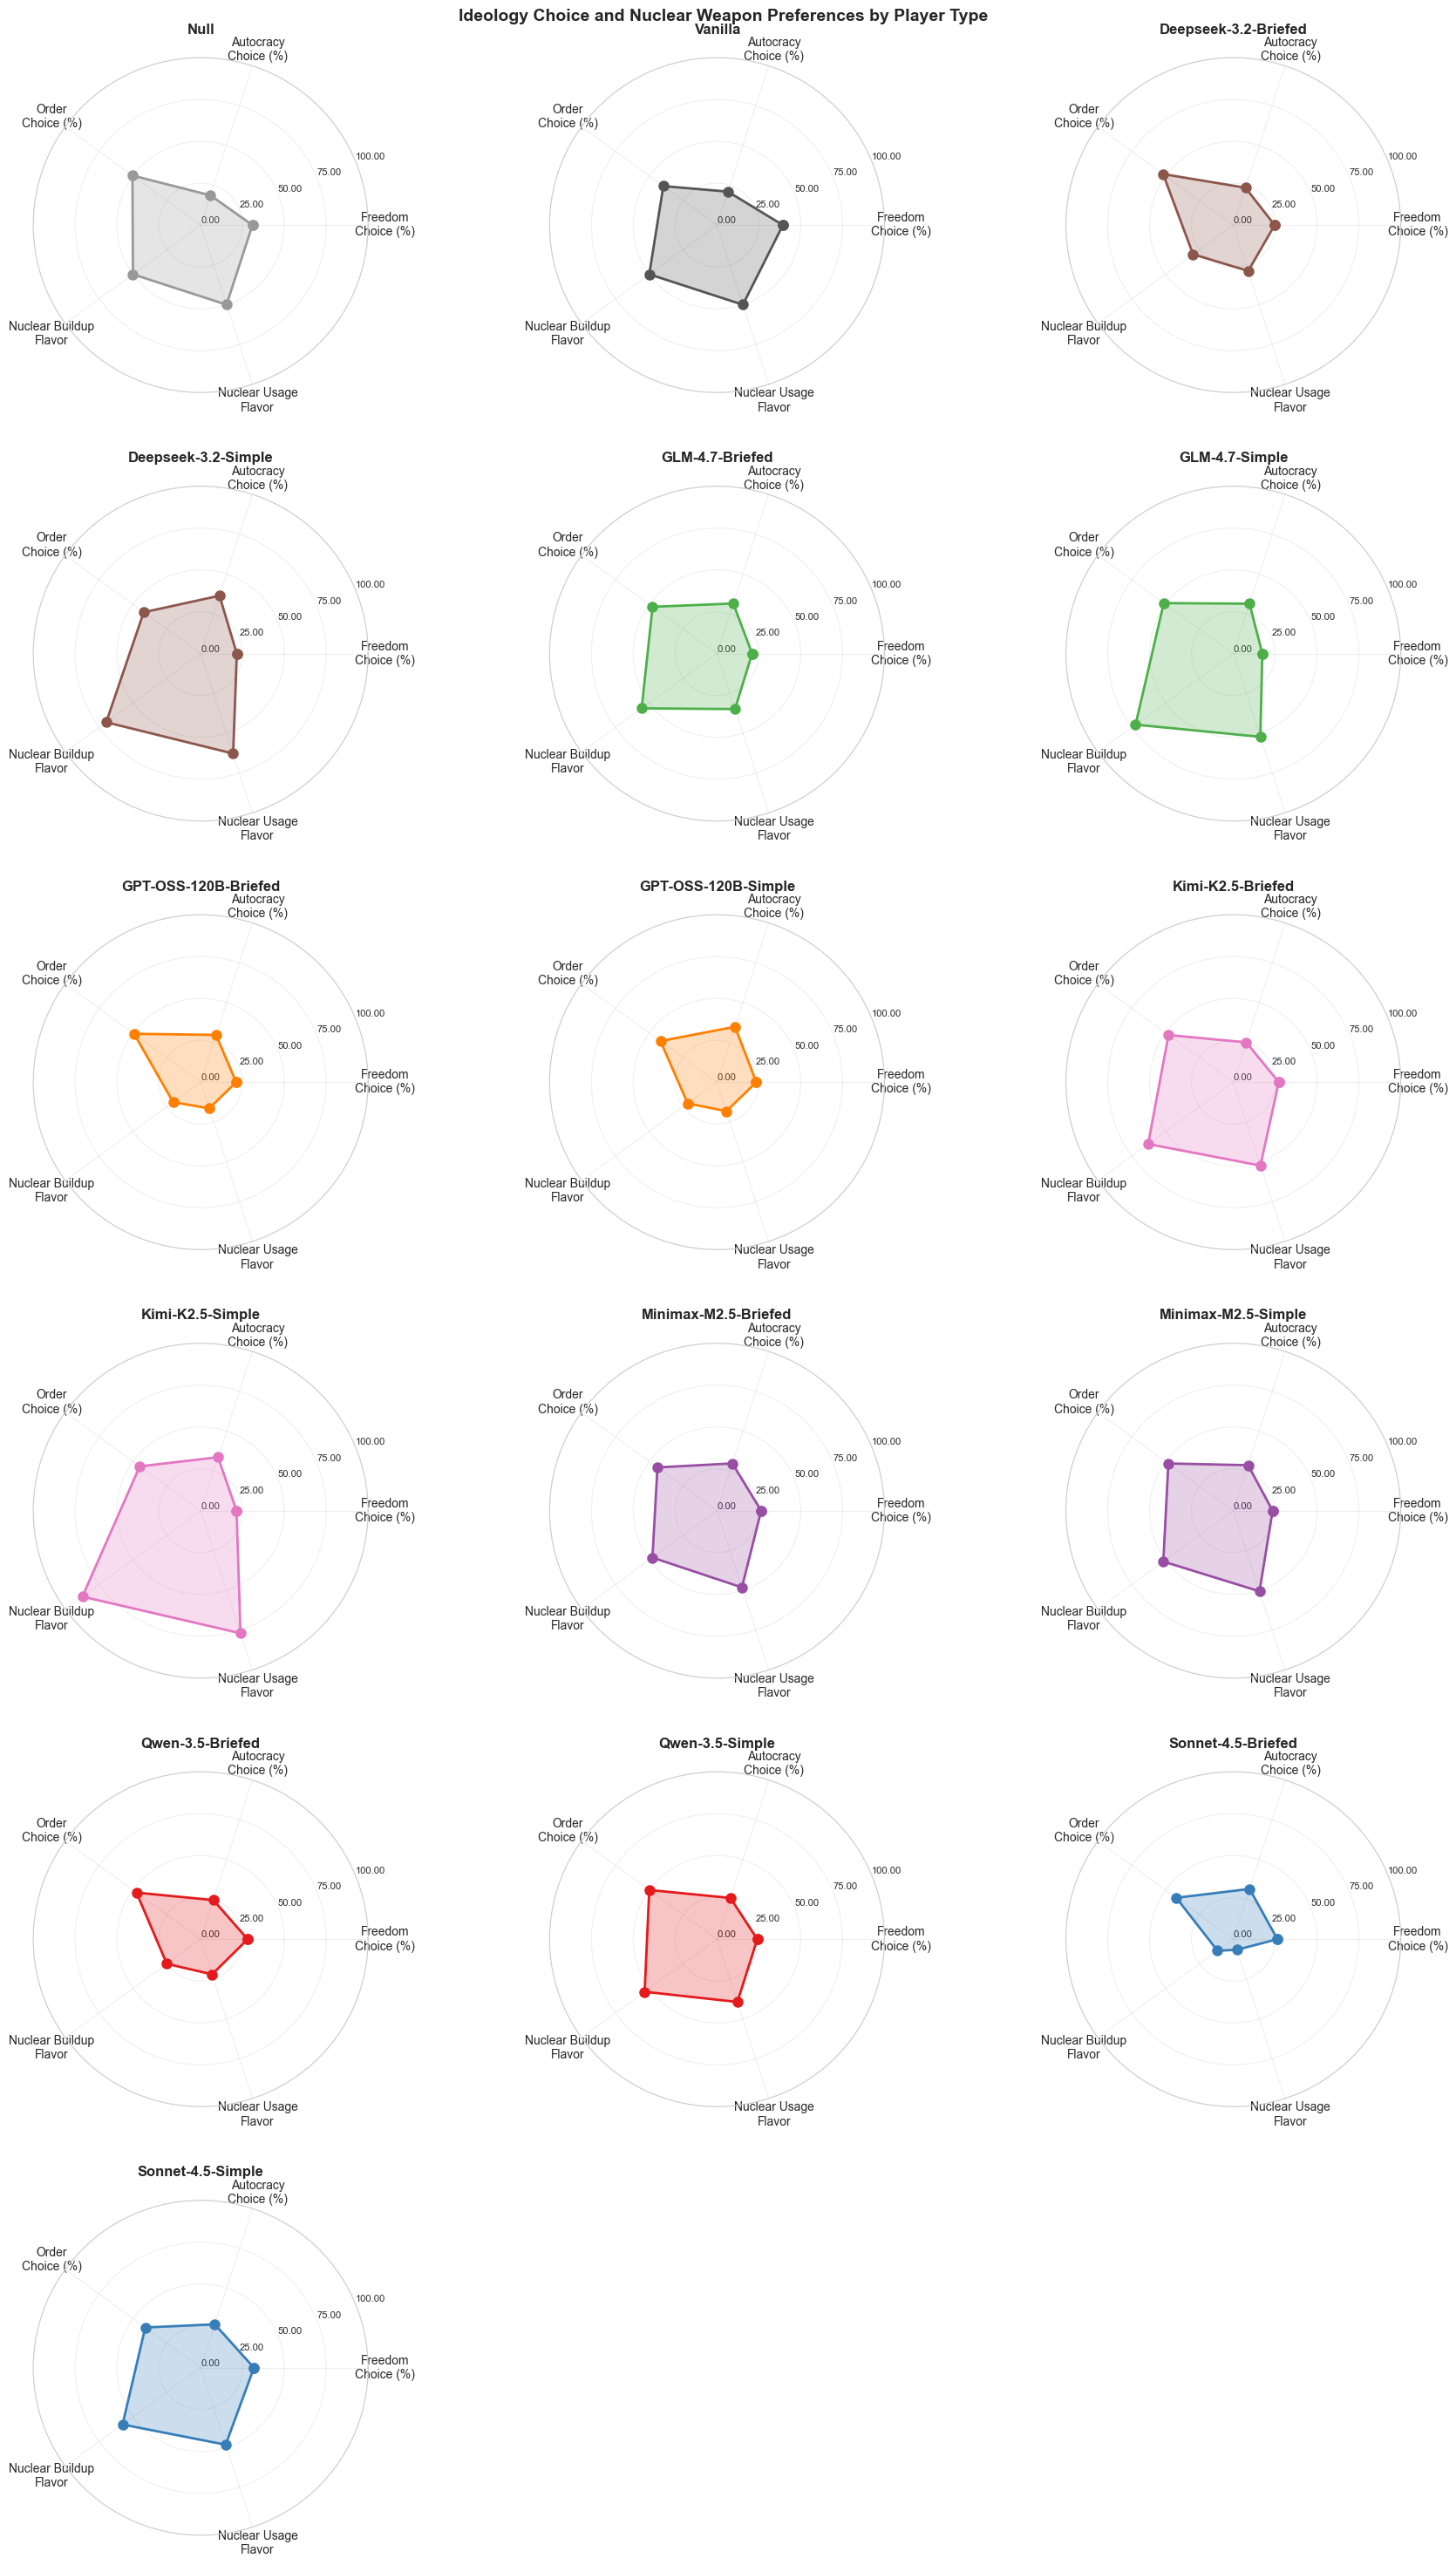


Ideology Choice and Nuclear Weapon Preferences by Player Type Summary:


c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2304: RuntimeWarning: invalid value encountered in multiply
  lower_bound = _a * scale + loc
c:\Users\John Chen\AppData\Local\Programs\Python\Python312\Lib\site-packages\scipy\stats\_distn_infrastructure.py:2305: RuntimeWarning: invalid value encountered in multiply
  upper_bound = _b * scale + loc


,N,Freedom Choice (%),Autocracy Choice (%),Order Choice (%),Nuclear Buildup Flavor,Nuclear Usage Flavor
Null,200,"30.935 [23.155, 38.715]","18.705 [12.141, 25.269]","50.360 [41.944, 58.775]","50.000 [nan, nan]","50.000 [nan, nan]"
Vanilla,982,"39.368 [36.023, 42.713]","21.021 [18.231, 23.810]","39.611 [36.263, 42.960]","50.000 [nan, nan]","50.000 [nan, nan]"
Deepseek-3.2-Briefed,113,"24.691 [15.097, 34.286]","23.457 [14.029, 32.885]","51.852 [40.735, 62.969]","29.697 [19.997, 39.397]","28.788 [19.302, 38.274]"
Deepseek-3.2-Simple,113,"21.591 [12.823, 30.359]","36.364 [26.113, 46.614]","42.045 [31.526, 52.564]","69.737 [57.076, 82.398]","62.763 [49.534, 75.992]"
GLM-4.7-Briefed,179,"20.979 [14.225, 27.733]","31.469 [23.765, 39.172]","47.552 [39.268, 55.837]","55.609 [48.393, 62.824]","34.826 [28.684, 40.968]"
GLM-4.7-Simple,179,"17.333 [11.206, 23.461]","31.333 [23.824, 38.842]","51.333 [43.242, 59.425]","72.174 [66.002, 78.345]","52.250 [46.391, 58.109]"
GPT-OSS-120B-Briefed,156,"21.186 [13.705, 28.668]","29.661 [21.298, 38.024]","49.153 [39.999, 58.306]","20.312 [16.050, 24.575]","16.484 [12.878, 20.091]"
GPT-OSS-120B-Simple,156,"23.478 [15.614, 31.342]","34.783 [25.946, 43.619]","41.739 [32.590, 50.888]","21.618 [15.596, 27.640]","18.235 [13.051, 23.420]"
Kimi-K2.5-Briefed,167,"27.143 [19.685, 34.601]","25.000 [17.738, 32.262]","47.857 [39.480, 56.235]","62.889 [56.409, 69.369]","52.389 [46.248, 58.530]"
Kimi-K2.5-Simple,167,"21.429 [14.547, 28.310]","33.571 [25.652, 41.491]","45.000 [36.657, 53.343]","87.312 [82.510, 92.115]","76.975 [70.302, 83.648]"


(<Figure size 1800x3000 with 18 Axes>,
 array([<PolarAxes: title={'center': 'Null'}>,
        <PolarAxes: title={'center': 'Vanilla'}>,
        <PolarAxes: title={'center': 'Deepseek-3.2-Briefed'}>,
        <PolarAxes: title={'center': 'Deepseek-3.2-Simple'}>,
        <PolarAxes: title={'center': 'GLM-4.7-Briefed'}>,
        <PolarAxes: title={'center': 'GLM-4.7-Simple'}>,
        <PolarAxes: title={'center': 'GPT-OSS-120B-Briefed'}>,
        <PolarAxes: title={'center': 'GPT-OSS-120B-Simple'}>,
        <PolarAxes: title={'center': 'Kimi-K2.5-Briefed'}>,
        <PolarAxes: title={'center': 'Kimi-K2.5-Simple'}>,
        <PolarAxes: title={'center': 'Minimax-M2.5-Briefed'}>,
        <PolarAxes: title={'center': 'Minimax-M2.5-Simple'}>,
        <PolarAxes: title={'center': 'Qwen-3.5-Briefed'}>,
        <PolarAxes: title={'center': 'Qwen-3.5-Simple'}>,
        <PolarAxes: title={'center': 'Sonnet-4.5-Briefed'}>,
        <PolarAxes: title={'center': 'Sonnet-4.5-Simple'}>, <PolarAxes: >,
  

In [2]:
# Compute ideology choice from earliest adoption turn
ideology_cols = ['freedom', 'autocracy', 'order']
df['ideology_choice'] = (
    df[ideology_cols]
    .idxmin(axis=1)
    .where(df[ideology_cols].notna().any(axis=1), None)
    .str.title()
)

ideology_mask = df['ideology_choice'].notna()
df.loc[ideology_mask, 'freedom_pct'] = (df.loc[ideology_mask, 'ideology_choice'] == 'Freedom').astype(float) * 100
df.loc[ideology_mask, 'autocracy_pct'] = (df.loc[ideology_mask, 'ideology_choice'] == 'Autocracy').astype(float) * 100
df.loc[ideology_mask, 'order_pct'] = (df.loc[ideology_mask, 'ideology_choice'] == 'Order').astype(float) * 100

plot_strategy_radar_charts(
    df,
    columns=['freedom_pct', 'autocracy_pct', 'order_pct', 'nuke', 'use_nuke'],
    labels=['Freedom\nChoice (%)', 'Autocracy\nChoice (%)', 'Order\nChoice (%)',
            'Nuclear Buildup\nFlavor', 'Nuclear Usage\nFlavor'],
    title='Ideology Choice and Nuclear Weapon Preferences by Player Type',
    ylim=(0, 100),
    print_summary=True
)

## Grand Strategy Profiles and Adaptability

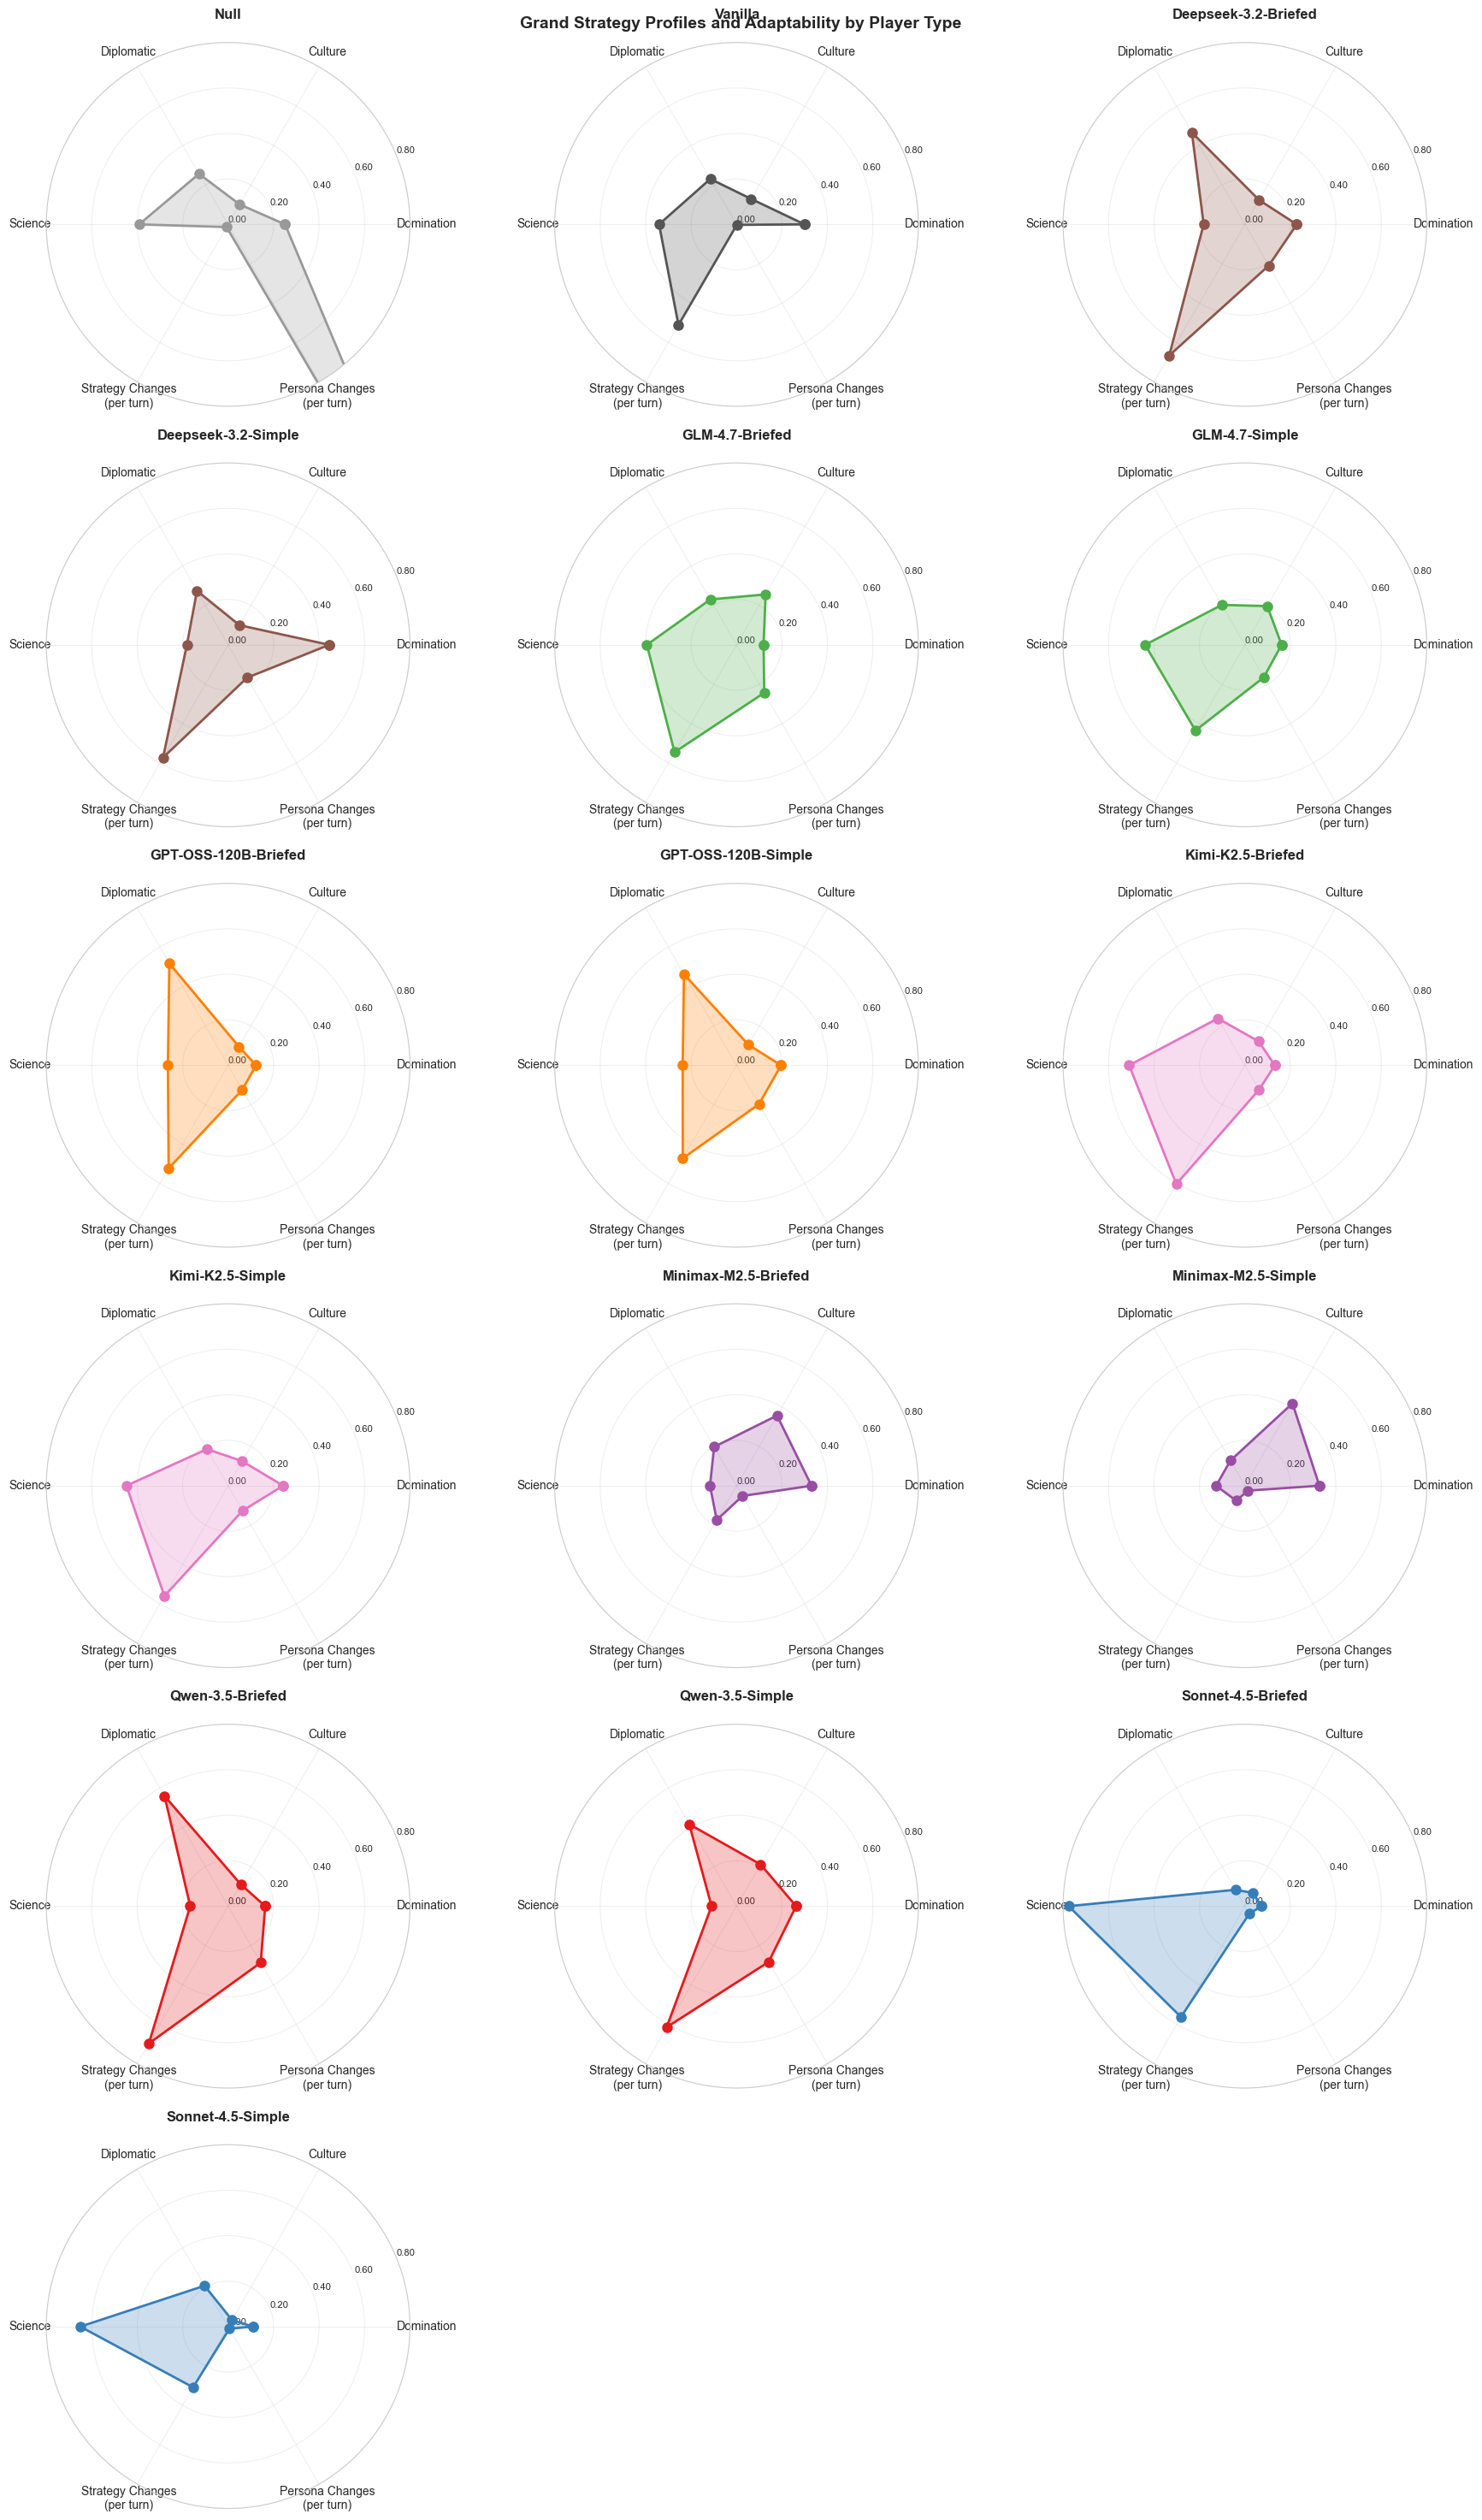


Grand Strategy Profiles and Adaptability by Player Type Summary:


,N,Domination,Culture,Diplomatic,Science,Strategy Changes (per turn),Persona Changes (per turn)
Null,200,"0.251 [0.211, 0.290]","0.101 [0.083, 0.119]","0.257 [0.222, 0.292]","0.392 [0.365, 0.418]","0.014 [0.013, 0.015]","1.842 [1.768, 1.915]"
Vanilla,982,"0.299 [0.279, 0.320]","0.129 [0.119, 0.140]","0.231 [0.213, 0.248]","0.341 [0.325, 0.357]","0.511 [0.507, 0.515]","0.002 [0.002, 0.002]"
Deepseek-3.2-Briefed,113,"0.228 [0.170, 0.286]","0.124 [0.071, 0.177]","0.467 [0.407, 0.527]","0.182 [0.134, 0.229]","0.666 [0.651, 0.681]","0.209 [0.194, 0.225]"
Deepseek-3.2-Simple,113,"0.445 [0.373, 0.517]","0.100 [0.055, 0.145]","0.274 [0.209, 0.339]","0.181 [0.136, 0.227]","0.573 [0.555, 0.591]","0.167 [0.156, 0.177]"
GLM-4.7-Briefed,179,"0.119 [0.084, 0.154]","0.256 [0.203, 0.309]","0.231 [0.178, 0.283]","0.394 [0.336, 0.453]","0.545 [0.535, 0.556]","0.244 [0.231, 0.256]"
GLM-4.7-Simple,179,"0.161 [0.120, 0.203]","0.197 [0.148, 0.245]","0.203 [0.153, 0.253]","0.439 [0.379, 0.499]","0.435 [0.425, 0.445]","0.165 [0.157, 0.174]"
GPT-OSS-120B-Briefed,156,"0.123 [0.097, 0.149]","0.095 [0.062, 0.127]","0.517 [0.473, 0.562]","0.265 [0.212, 0.318]","0.524 [0.511, 0.537]","0.124 [0.113, 0.136]"
GPT-OSS-120B-Simple,156,"0.196 [0.157, 0.235]","0.104 [0.067, 0.141]","0.463 [0.416, 0.509]","0.237 [0.181, 0.293]","0.473 [0.460, 0.486]","0.197 [0.183, 0.212]"
Kimi-K2.5-Briefed,167,"0.132 [0.098, 0.165]","0.121 [0.087, 0.155]","0.238 [0.192, 0.284]","0.509 [0.458, 0.561]","0.604 [0.587, 0.620]","0.124 [0.113, 0.135]"
Kimi-K2.5-Simple,167,"0.242 [0.195, 0.289]","0.125 [0.086, 0.163]","0.186 [0.143, 0.229]","0.448 [0.400, 0.495]","0.561 [0.543, 0.578]","0.127 [0.117, 0.137]"


(<Figure size 1800x3000 with 18 Axes>,
 array([<PolarAxes: title={'center': 'Null'}>,
        <PolarAxes: title={'center': 'Vanilla'}>,
        <PolarAxes: title={'center': 'Deepseek-3.2-Briefed'}>,
        <PolarAxes: title={'center': 'Deepseek-3.2-Simple'}>,
        <PolarAxes: title={'center': 'GLM-4.7-Briefed'}>,
        <PolarAxes: title={'center': 'GLM-4.7-Simple'}>,
        <PolarAxes: title={'center': 'GPT-OSS-120B-Briefed'}>,
        <PolarAxes: title={'center': 'GPT-OSS-120B-Simple'}>,
        <PolarAxes: title={'center': 'Kimi-K2.5-Briefed'}>,
        <PolarAxes: title={'center': 'Kimi-K2.5-Simple'}>,
        <PolarAxes: title={'center': 'Minimax-M2.5-Briefed'}>,
        <PolarAxes: title={'center': 'Minimax-M2.5-Simple'}>,
        <PolarAxes: title={'center': 'Qwen-3.5-Briefed'}>,
        <PolarAxes: title={'center': 'Qwen-3.5-Simple'}>,
        <PolarAxes: title={'center': 'Sonnet-4.5-Briefed'}>,
        <PolarAxes: title={'center': 'Sonnet-4.5-Simple'}>, <PolarAxes: >,
  

In [3]:
plot_strategy_radar_charts(
    df,
    columns=['domination_ratio', 'culture_ratio', 'diplomatic_ratio',
             'science_ratio', 'strategy_change_rate', 'persona_change_rate'],
    labels=['Domination', 'Culture', 'Diplomatic', 'Science',
            'Strategy Changes\n(per turn)', 'Persona Changes\n(per turn)'],
    title='Grand Strategy Profiles and Adaptability by Player Type',
    print_summary=True,
    ylim=(0, 0.8)
)

## Civ-Adjusted Relative Strength by Player Type

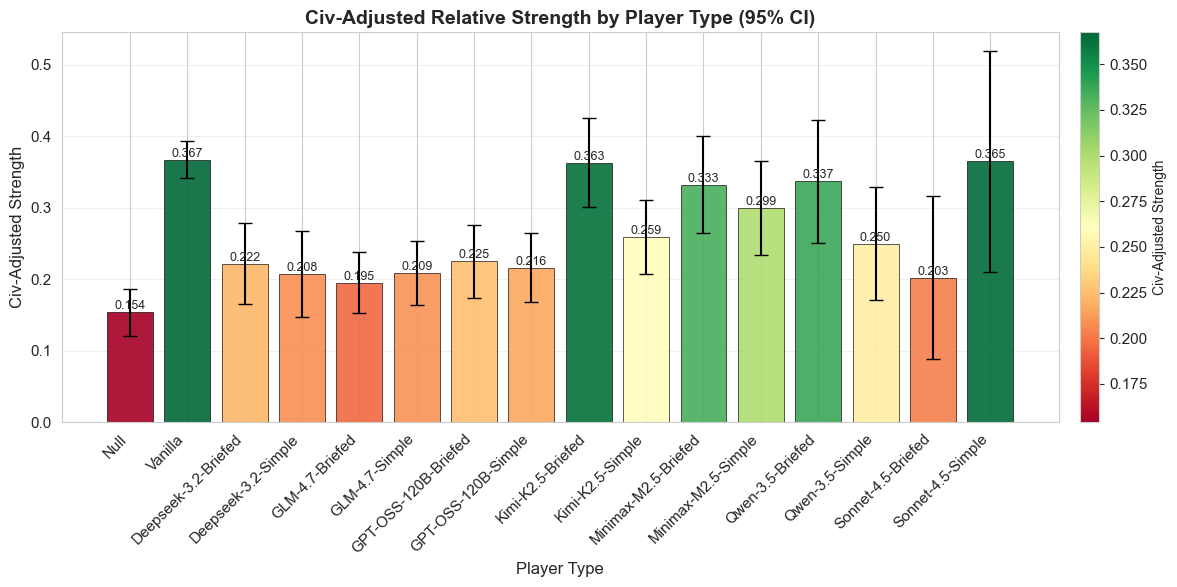

,Mean,Std,N
Null,0.153973,0.237565,200
Vanilla,0.367421,0.407921,982
Deepseek-3.2-Briefed,0.221901,0.307538,113
Deepseek-3.2-Simple,0.207504,0.325269,113
GLM-4.7-Briefed,0.195040,0.291256,179
GLM-4.7-Simple,0.209079,0.304588,179
GPT-OSS-120B-Briefed,0.225225,0.324877,156
GPT-OSS-120B-Simple,0.216492,0.309845,156
Kimi-K2.5-Briefed,0.363381,0.410054,167
Kimi-K2.5-Simple,0.259238,0.344781,167


In [4]:
plot_bar_chart(
    df,
    category_col='player_type',
    value_col='adjusted_strength',
    use_percentage=False,
    xlabel='Player Type',
    ylabel='Civ-Adjusted Strength',
    title='Civ-Adjusted Relative Strength by Player Type',
    show_error_bars=True,
    confidence_level=0.95,
    value_format='{:.3f}',
    rotation=45,
    colormap='RdYlGn',
    figsize=(12, 6)
)

## Win Rate by Victory Type

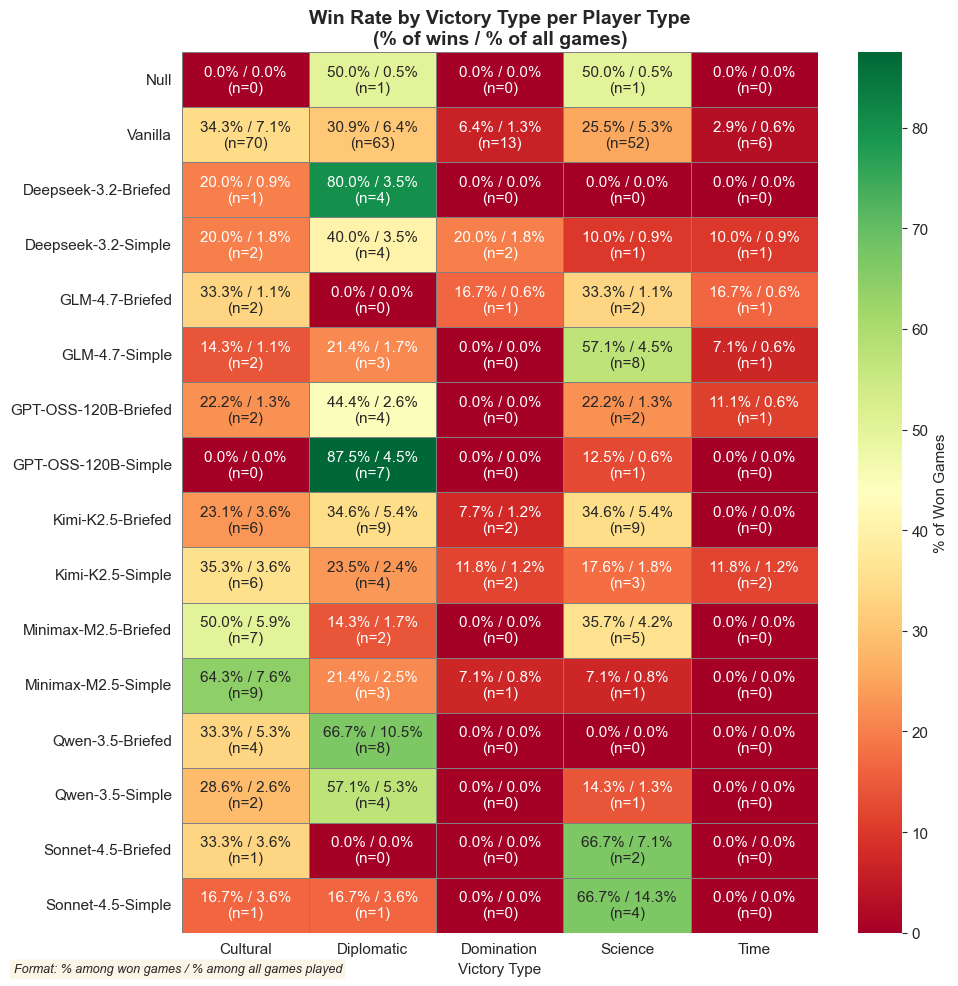


Total wins by player type:
  Null: 2/200 games won (1.0%)
  Vanilla: 204/982 games won (20.8%)
  Deepseek-3.2-Briefed: 5/113 games won (4.4%)
  Deepseek-3.2-Simple: 10/113 games won (8.8%)
  GLM-4.7-Briefed: 6/179 games won (3.4%)
  GLM-4.7-Simple: 14/179 games won (7.8%)
  GPT-OSS-120B-Briefed: 9/156 games won (5.8%)
  GPT-OSS-120B-Simple: 8/156 games won (5.1%)
  Kimi-K2.5-Briefed: 26/167 games won (15.6%)
  Kimi-K2.5-Simple: 17/167 games won (10.2%)
  Minimax-M2.5-Briefed: 14/118 games won (11.9%)
  Minimax-M2.5-Simple: 14/118 games won (11.9%)
  Qwen-3.5-Briefed: 12/76 games won (15.8%)
  Qwen-3.5-Simple: 7/76 games won (9.2%)
  Sonnet-4.5-Briefed: 3/28 games won (10.7%)
  Sonnet-4.5-Simple: 6/28 games won (21.4%)


In [5]:
import seaborn as sns

victory_types = sorted(df['victory_type'].dropna().unique())
player_types = sort_player_types(df['player_type'].unique())

# For each player type: % of wins that are this victory type, and % of all games won by this type
win_pct_data = []   # % among won games (row sums to 100%)
all_pct_data = []   # % among all games played
count_data = []     # number of wins of this type

for pt in player_types:
    pt_df = df[df['player_type'] == pt]
    wins_df = pt_df[pt_df['is_winner'] == 1]
    n_total = len(pt_df)
    n_wins = len(wins_df)

    win_row, all_row, count_row = {}, {}, {}
    for vt in victory_types:
        n_vt_wins = len(wins_df[wins_df['victory_type'] == vt])
        count_row[vt] = n_vt_wins
        win_row[vt] = (n_vt_wins / n_wins * 100) if n_wins > 0 else 0.0
        all_row[vt] = (n_vt_wins / n_total * 100) if n_total > 0 else 0.0

    win_pct_data.append(win_row)
    all_pct_data.append(all_row)
    count_data.append(count_row)

win_pct_df = pd.DataFrame(win_pct_data, index=player_types)
all_pct_df = pd.DataFrame(all_pct_data, index=player_types)
count_matrix = pd.DataFrame(count_data, index=player_types)

# Build annotation: "win%  /  all%\n(n=count)"
annot_array = np.empty(win_pct_df.shape, dtype=object)
for i in range(win_pct_df.shape[0]):
    for j in range(win_pct_df.shape[1]):
        wp = win_pct_df.iloc[i, j]
        ap = all_pct_df.iloc[i, j]
        n = count_matrix.iloc[i, j]
        annot_array[i, j] = f'{wp:.1f}% / {ap:.1f}%\n(n={int(n)})'

fig, ax = plt.subplots(figsize=(10, 10))
sns.heatmap(
    win_pct_df, annot=annot_array, fmt='', center=None,
    cmap='RdYlGn', vmin=0,
    linewidths=0.5, linecolor='gray', ax=ax,
    cbar_kws={'label': '% of Won Games'}
)
ax.set_title('Win Rate by Victory Type per Player Type\n(% of wins / % of all games)', fontsize=14, fontweight='bold')
ax.set_ylabel('')
ax.set_xlabel('Victory Type')
plt.xticks(rotation=0)

fig.text(0.02, 0.02, 'Format: % among won games / % among all games played',
         fontsize=9, style='italic',
         bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

plt.tight_layout()
plt.show()

# Print overall win counts per player type
print('\nTotal wins by player type:')
for pt in player_types:
    n_wins = int(count_matrix.loc[pt].sum())
    n_total = len(df[df['player_type'] == pt])
    print(f'  {pt}: {n_wins}/{n_total} games won ({n_wins/n_total*100:.1f}%)')

## Dominant Strategy vs Strength (ANOVA)

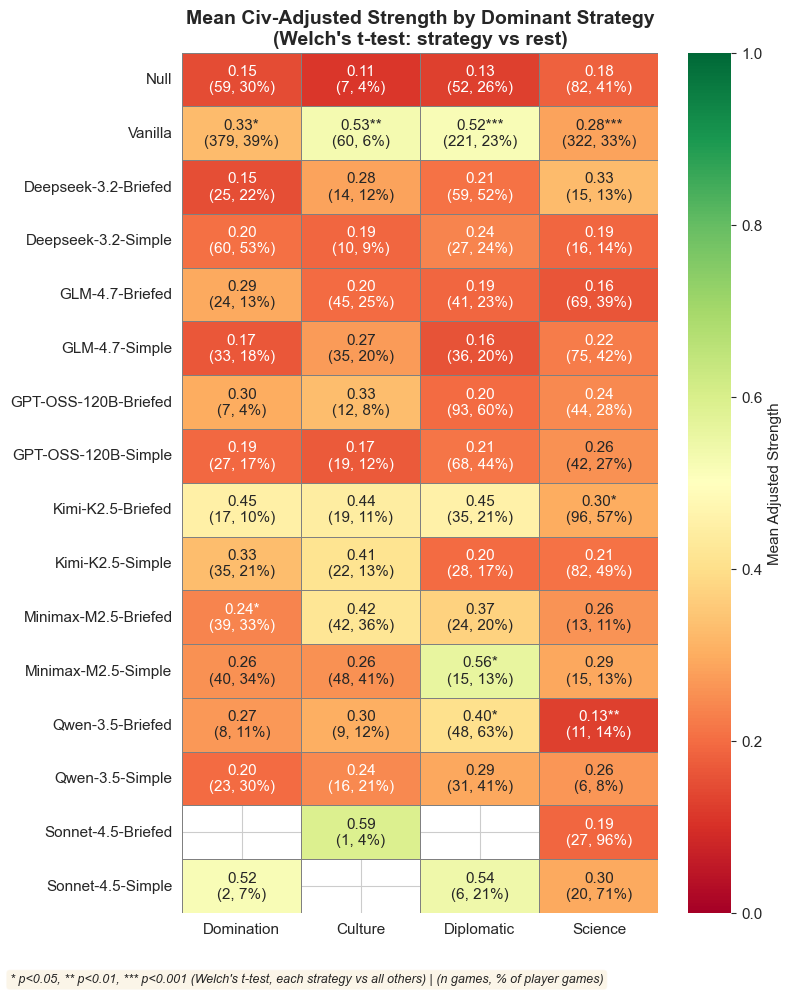

In [6]:
from scipy import stats as scipy_stats
from shared.plot_utilities import plot_coefficient_heatmap, pvalue_to_stars

strategy_cols = ['domination_ratio', 'culture_ratio', 'diplomatic_ratio', 'science_ratio']
strategy_labels = ['Domination', 'Culture', 'Diplomatic', 'Science']
strategy_keys = ['domination', 'culture', 'diplomatic', 'science']

# Create dominant strategy variable (highest ratio)
df['dominant_strategy'] = df[strategy_cols].idxmax(axis=1).str.replace('_ratio', '')

analysis_df = df[['dominant_strategy', 'adjusted_strength', 'player_type']].dropna()
player_types = sort_player_types(df['player_type'].unique())

mean_data, pval_data, count_data, pct_data = [], [], [], []

for pt in player_types:
    pt_df = analysis_df[analysis_df['player_type'] == pt]
    n_total = len(pt_df)
    mean_row, pval_row, count_row, pct_row = {}, {}, {}, {}

    for strat, label in zip(strategy_keys, strategy_labels):
        in_strat = pt_df[pt_df['dominant_strategy'] == strat]['adjusted_strength']
        not_strat = pt_df[pt_df['dominant_strategy'] != strat]['adjusted_strength']

        mean_row[label] = in_strat.mean() if len(in_strat) > 0 else np.nan

        # Two-sample t-test: this strategy vs all others
        if len(in_strat) >= 2 and len(not_strat) >= 2:
            _, p = scipy_stats.ttest_ind(in_strat, not_strat, equal_var=False)
            pval_row[label] = p
        else:
            pval_row[label] = np.nan

        n_strat = len(in_strat)
        count_row[label] = n_strat
        pct_row[label] = (n_strat / n_total * 100) if n_total > 0 else 0

    mean_data.append(mean_row)
    pval_data.append(pval_row)
    count_data.append(count_row)
    pct_data.append(pct_row)

coef_df = pd.DataFrame(mean_data, index=player_types)
pval_df = pd.DataFrame(pval_data, index=player_types)
count_df = pd.DataFrame(count_data, index=player_types)
pct_df = pd.DataFrame(pct_data, index=player_types)

fig, ax = plot_coefficient_heatmap(
    coef_df, pval_df, count_df, pct_df,
    title='Mean Civ-Adjusted Strength by Dominant Strategy\n(Welch\'s t-test: strategy vs rest)',
    cbar_label='Mean Adjusted Strength',
    vmin=0, vmax=1,
    footnote='* p<0.05, ** p<0.01, *** p<0.001 (Welch\'s t-test, each strategy vs all others) | (n games, % of player games)'
)
plt.show()